# Fit M1-split - rev01

| | |
|---|---|
| **Tube** | `2 % H2O in DEC, 12/11/2026` (5 vol% TMSPa + 2 vol% H₂O in neat DEC, 22.3 °C, $t_0$ known) |
| **Solvation** | MACE MD in neat DEC (`tank_api_snapshot_2026-11-12.json`) |
| **Runs** | `kin_M1_DEC2pct-261112_md1112` (M1) · `kin_M1-split_DEC2pct-261112_md1112` (M1-split) · `fit8_M1-steps_S1-tube` (M1-steps reference) |

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / 'kinetics').is_dir() else Path.cwd().parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

import kinetics
from kinetics.constants import KCAL_EV, ZERO_CELSIUS_K
from kinetics.data import load_lab_observables
from kinetics.data.network import get_active_network
from kinetics.fitting import apply_fit_config, load_fit_result
from kinetics.fitting.reporting import evaluate_fit, simulate_fit_trajectories, tabulate_fit_shares
from kinetics.thermo.reaction import calculate_network_thermo
from demo import fit_plots, style
from demo.reactor_plots import CONCENTRATION_PANELS, plot_concentration_panels

assert Path(kinetics.__file__).parents[1] == REPO
style.apply_style()
pd.set_option('display.max_colwidth', None)

TUBE = '2 % H2O in DEC, 12/11/2026'
RUN_M1 = REPO / 'notebooks' / 'results' / 'kin_M1_DEC2pct-261112_md1112'
RUN_SPLIT = REPO / 'notebooks' / 'results' / 'kin_M1-split_DEC2pct-261112_md1112'
RUN_STEPS = REPO / 'notebooks' / 'results' / 'fit8_M1-steps_S1-tube'

---
## 1. Model, equations, and M1-steps

### 1.1 Reaction network and barrier grouping

| ID | Reaction | M1 class | M1-split class |
|---|---|---|---|
| R1 | TMSPA + H₂O ⇌ BMSPA + TMSOH | hydrolysis | **hydrolysis_R1** |
| R2 | BMSPA + H₂O ⇌ MMSPA + TMSOH | hydrolysis | **hydrolysis_R23** |
| R3 | MMSPA + H₂O ⇌ H₃PO₄ + TMSOH | hydrolysis | **hydrolysis_R23** |
| N12 | BMSPA + H₂O ⇌ H₃PO₄ + HMDSO | hydrolysis (follows R2) | **hydrolysis_R23** |
| N15 | TMSPA + H₂O ⇌ MMSPA + HMDSO | hydrolysis (follows R1) | **hydrolysis_N15** |
| R4 | 2 TMSOH ⇌ HMDSO + H₂O | condensation | condensation |
| R5–R7 | Phosphate + TMSOH ⇌ next + HMDSO | transfer | transfer |
| R8–R9 | EC + TMSOH / TMSOEG ⇌ TMSOEG / TMSOdiEG + CO₂ | solvent_attack | solvent_attack (inactive: no EC) |
| N10, N11, N13, N14 | Silyl exchanges | exchange (fixed 1.15 eV) | exchange (fixed 1.15 eV) |

### 1.2 Equations

- **Reaction energy** (with freed solvation shifts $\mathbf{d}$ on R1 and R2 in M1-split, applied via species shifts so cycles close):
$$\Delta G_{\mathrm{rxn}, j} = \Delta G_{\mathrm{gas}, j} + \Delta\Delta E_{\mathrm{solv}, j} + d_j$$

- **Marcus barrier and Eyring rate constant**:
$$\Delta G_{f, j}^\ddagger = g_c\left(1 + \frac{\Delta G_{\mathrm{rxn}, j}}{4 g_c}\right)^2, \qquad k_{f, j}(T) = \frac{k_B T}{h}\exp\!\left(-\frac{\Delta G_{f, j}^\ddagger}{k_B T}\right), \qquad k_{r, j}(T) = \frac{k_{f, j}(T)}{K_{\mathrm{eq}, j}(T)}$$

- **Objective function and fit rule**:
$$z_i = \frac{y_{\mathrm{model}, i} - y_{\mathrm{NMR}, i}}{\sigma_i}, \qquad \chi^2 = \sum_i z_i^2 + \mathbf{d}^\top \Sigma_{\mathrm{solv}}^{-1}\mathbf{d}, \qquad \text{fits if } \max_i |z_i| \le 3$$

### 1.3 How M1-steps works

- **Multi-tube chain (`fit8_M1-steps_S1-tube`)**: fits one tube at a time (`S1.tube` → `S2` → `S3` → `S4` → `S5`). Unreached barriers are held at the upper edge of their box; each step fixes its fitted barrier for later steps and scores all tubes.
- **Single-tube run (`K1`)**: when a single tube has a known mixing time $t_0$ (`2 % H2O in DEC, 12/11/2026`), all active parameters are fitted directly in one step `K1`.

In [2]:
steps_df = pd.read_csv(RUN_STEPS / 'steps_summary.csv')
s10 = steps_df[steps_df['scenario'] == '10 min'][
    ['step', 'tubes fitted', 'free', 'from', 'g hydrolysis', 'g transfer', 'g condensation', 'g solvent_attack', 'chi2', 'max |z|', 'fits']
].copy()
s10.columns = ['step', 'tube fitted', 'freed', 'from', 'g hyd', 'g trans', 'g cond', 'g solv', 'χ²', 'max |z|', 'fits']
s10 = s10.fillna('—')
display(s10.style.hide(axis='index').format({'g hyd': '{:.3f}', 'g trans': '{:.3f}', 'g cond': '{:.3f}', 'g solv': '{:.3f}',
                                             'χ²': '{:.2f}', 'max |z|': '{:.2f}'})
        .set_caption('M1-steps chain at 10 min reading (fit8_M1-steps_S1-tube)'))

step,tube fitted,freed,from,g hyd,g trans,g cond,g solv,χ²,max |z|,fits
S1,"TMSOH, glovebox","g condensation, g solvent_attack",off,1.700,1.500,1.184,1.223,0.00,0.03,True
S1.tube,"TMSOH, probe","g condensation, g solvent_attack",off,1.700,1.500,1.129,1.222,0.68,0.53,True
S2,TMSPa + TMSOH (A),g transfer,S1.tube,1.700,0.904,1.129,1.222,1.81,0.98,True
S3,TMSPa alone,g hydrolysis,S2,1.062,0.904,1.129,1.222,6.73,1.56,True
S2b,TMSPa + TMSOH (A),g transfer,S3,1.062,0.904,1.129,1.222,1.81,0.98,True
S4,0.5 % H2O,g hydrolysis,S3,1.246,0.904,1.129,1.222,12.88,2.84,True
S5,2 % H2O,—,S3,1.062,0.904,1.129,1.222,5314.33,51.62,False


---
## 2. Comparison of barrier groupings & fitted parameters

In [3]:
fit_m1 = load_fit_result(str(RUN_M1 / 'steps' / 'M1__K1__10_min.json'))
fit_sp = load_fit_result(str(RUN_SPLIT / 'steps' / 'M1-split-dG__K1__10_min.json'))

groupings = pd.DataFrame([
    {'Structure': 'M1 (stored)', 'Hydrolysis grouping': 'R1, R2, R3, N15 together', 'Free ΔG': 'none',
     'χ²': fit_m1['chi2'], 'max |z|': fit_m1['max_abs_z'], 'Fits?': fit_m1['fits']},
    {'Structure': 'Trial A (scratch)', 'Hydrolysis grouping': 'R1 + N15 | R2 + R3', 'Free ΔG': 'none',
     'χ²': 91.5, 'max |z|': 6.93, 'Fits?': False},
    {'Structure': 'Trial B (scratch)', 'Hydrolysis grouping': 'R1 + N15 | R2 + R3', 'Free ΔG': 'R1, R2',
     'χ²': 37.1, 'max |z|': 3.28, 'Fits?': False},
    {'Structure': 'Trial D (scratch)', 'Hydrolysis grouping': 'R1 | R2 + R3 + N15', 'Free ΔG': 'R1, R2',
     'χ²': 27.4, 'max |z|': 3.64, 'Fits?': False},
    {'Structure': 'M1-split (stored)', 'Hydrolysis grouping': 'R1 | R2 + R3 | N15', 'Free ΔG': 'R1, R2',
     'χ²': fit_sp['chi2'], 'max |z|': fit_sp['max_abs_z'], 'Fits?': fit_sp['fits']},
])
display(groupings.style.hide(axis='index').format({'χ²': '{:.1f}', 'max |z|': '{:.2f}'})
        .set_caption(f'Comparison of barrier groupings on {TUBE} (MD 2026-11-12 solvation)'))

Structure,Hydrolysis grouping,Free ΔG,χ²,max |z|,Fits?
M1 (stored),"R1, R2, R3, N15 together",none,96.4,7.14,False
Trial A (scratch),R1 + N15 | R2 + R3,none,91.5,6.93,False
Trial B (scratch),R1 + N15 | R2 + R3,"R1, R2",37.1,3.28,False
Trial D (scratch),R1 | R2 + R3 + N15,"R1, R2",27.4,3.64,False
M1-split (stored),R1 | R2 + R3 | N15,"R1, R2",21.3,2.85,True


In [4]:
iv_m1 = pd.read_csv(RUN_M1 / 'steps_intervals.csv').set_index('parameter')
iv_sp = pd.read_csv(RUN_SPLIT / 'steps_intervals.csv').set_index('parameter')

LABELS = {
    'g hydrolysis': 'g hydrolysis (all)',
    'g hydrolysis_R1': 'g hydrolysis (R1)',
    'g hydrolysis_R23': 'g hydrolysis (R2, R3)',
    'g hydrolysis_N15': 'g hydrolysis (N15)',
    'g transfer': 'g transfer',
    'g condensation': 'g condensation',
    'g solvent_attack': 'g solvent attack',
    'dG R1': 'ΔG R1 shift',
    'dG R2': 'ΔG R2 shift',
}


def fmt_range(iv, key):
    if key not in iv.index:
        return '—'
    r = iv.loc[key]
    if r['status'] == 'interval':
        return f"{r['low']:.3f} to {r['high']:.3f}"
    if r['status'] == 'lower bound only':
        return f"≥ {r['low']:.3f}"
    if r['status'] == 'upper bound only':
        return f"≤ {r['high']:.3f}"
    return 'not determined'


order = ['g hydrolysis', 'g hydrolysis_R1', 'g hydrolysis_R23', 'g hydrolysis_N15',
         'g transfer', 'g condensation', 'g solvent_attack', 'dG R1', 'dG R2']
rows = []
for k in order:
    rows.append({
        'Parameter': LABELS[k],
        ('M1', 'value (eV)'): f"{fit_m1['theta'][k]:.3f}" if k in fit_m1['theta'] else '—',
        ('M1', '95% range (eV)'): fmt_range(iv_m1, k),
        ('M1', 'status'): iv_m1.loc[k, 'status'] if k in iv_m1.index else '—',
        ('M1-split', 'value (eV)'): f"{fit_sp['theta'][k]:+.3f}" if k.startswith('dG') else f"{fit_sp['theta'][k]:.3f}" if k in fit_sp['theta'] else '—',
        ('M1-split', '95% range (eV)'): fmt_range(iv_sp, k),
        ('M1-split', 'status'): iv_sp.loc[k, 'status'] if k in iv_sp.index else '—',
    })
rows.append({
    'Parameter': 'χ² (20 shares + prior)',
    ('M1', 'value (eV)'): f"{fit_m1['chi2']:.2f}", ('M1', '95% range (eV)'): '—', ('M1', 'status'): '—',
    ('M1-split', 'value (eV)'): f"{fit_sp['chi2']:.2f}", ('M1-split', '95% range (eV)'): '—', ('M1-split', 'status'): '—',
})
rows.append({
    'Parameter': 'max |z|',
    ('M1', 'value (eV)'): f"{fit_m1['max_abs_z']:.2f}", ('M1', '95% range (eV)'): fit_m1['worst'], ('M1', 'status'): str(fit_m1['fits']),
    ('M1-split', 'value (eV)'): f"{fit_sp['max_abs_z']:.2f}", ('M1-split', '95% range (eV)'): fit_sp['worst'], ('M1-split', 'status'): str(fit_sp['fits']),
})
param_df = pd.DataFrame(rows).set_index('Parameter')
param_df.columns = pd.MultiIndex.from_tuples([('' if isinstance(c, str) else c[0], c if isinstance(c, str) else c[1]) for c in param_df.columns])
display(param_df.style.set_caption(f'Fitted parameters on {TUBE}'))

In [5]:
apply_fit_config(RUN_SPLIT)
net = get_active_network()
thermo_comp = calculate_network_thermo(295.65, network=net)

rxns_show = ['R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7', 'N12', 'N15']
rxn_rows = []
for r in rxns_show:
    b1, b2 = fit_m1['barriers'][r], fit_sp['barriers'][r]
    rxn_rows.append({
        'Reaction': r,
        'Equation': thermo_comp.loc[r, 'equation'].replace('H2O', 'H₂O').replace('H3PO4', 'H₃PO₄'),
        'Class (M1-split)': 'hydrolysis_R1' if r == 'R1' else ('hydrolysis_R23' if r in ('R2', 'R3', 'N12') else ('hydrolysis_N15' if r == 'N15' else net[r]['class'])),
        'ΔG_rxn comp (eV)': b1['dG_rxn_eV'],
        'ΔG_rxn M1-split (eV)': b2['dG_rxn_eV'],
        'σ_solv (eV)': thermo_comp.loc[r, 'sigma_solv_eV'],
        'ΔG‡ M1 (eV)': b1['dG_barrier_eV'],
        'ΔG‡ M1-split (eV)': b2['dG_barrier_eV'],
    })
rxn_df = pd.DataFrame(rxn_rows).set_index('Reaction')
display(rxn_df.style.format({
    'ΔG_rxn comp (eV)': '{:+.3f}', 'ΔG_rxn M1-split (eV)': '{:+.3f}', 'σ_solv (eV)': '{:.3f}',
    'ΔG‡ M1 (eV)': '{:.3f}', 'ΔG‡ M1-split (eV)': '{:.3f}'
}).set_caption('Active reactions in neat DEC at 22.5 °C (computed vs M1-split)'))

,Equation,Class (M1-split),ΔG_rxn comp (eV),ΔG_rxn M1-split (eV),σ_solv (eV),ΔG‡ M1 (eV),ΔG‡ M1-split (eV)
Reaction,,,,,,,
R1,TMSPA + H₂O ⇌ BMSPA + TMSOH,hydrolysis_R1,-0.423,-0.413,0.170,0.857,0.873
R2,BMSPA + H₂O ⇌ MMSPA + TMSOH,hydrolysis_R23,+0.403,-0.092,0.246,1.269,1.091
R3,MMSPA + H₂O ⇌ H₃PO₄ + TMSOH,hydrolysis_R23,-0.035,-0.035,0.335,1.040,1.119
R4,2 TMSOH ⇌ HMDSO + H₂O,condensation,-0.242,-0.242,0.273,0.883,1.346
R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,transfer,-0.664,-0.655,0.279,0.884,0.364
R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,transfer,+0.162,-0.333,0.331,1.275,0.495
R7,MMSPA + TMSOH ⇌ H₃PO₄ + HMDSO,transfer,-0.277,-0.277,0.402,1.058,0.520
N12,BMSPA + H₂O ⇌ H₃PO₄ + HMDSO,hydrolysis_R23,+0.127,-0.368,0.358,1.122,0.959
N15,TMSPA + H₂O ⇌ MMSPA + HMDSO,hydrolysis_N15,-0.261,-0.746,0.317,0.931,0.955


---
## 3. Concentration plots and reaction energetics

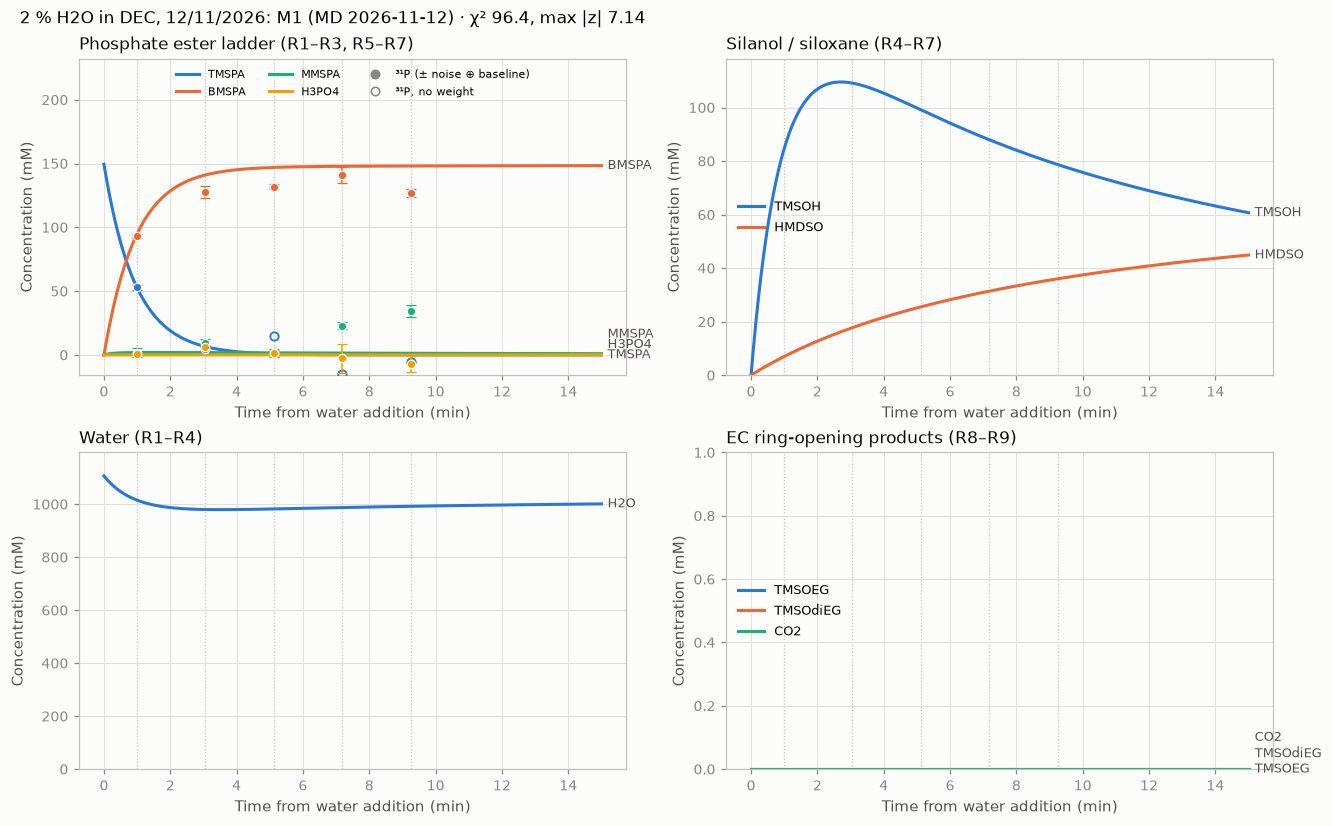

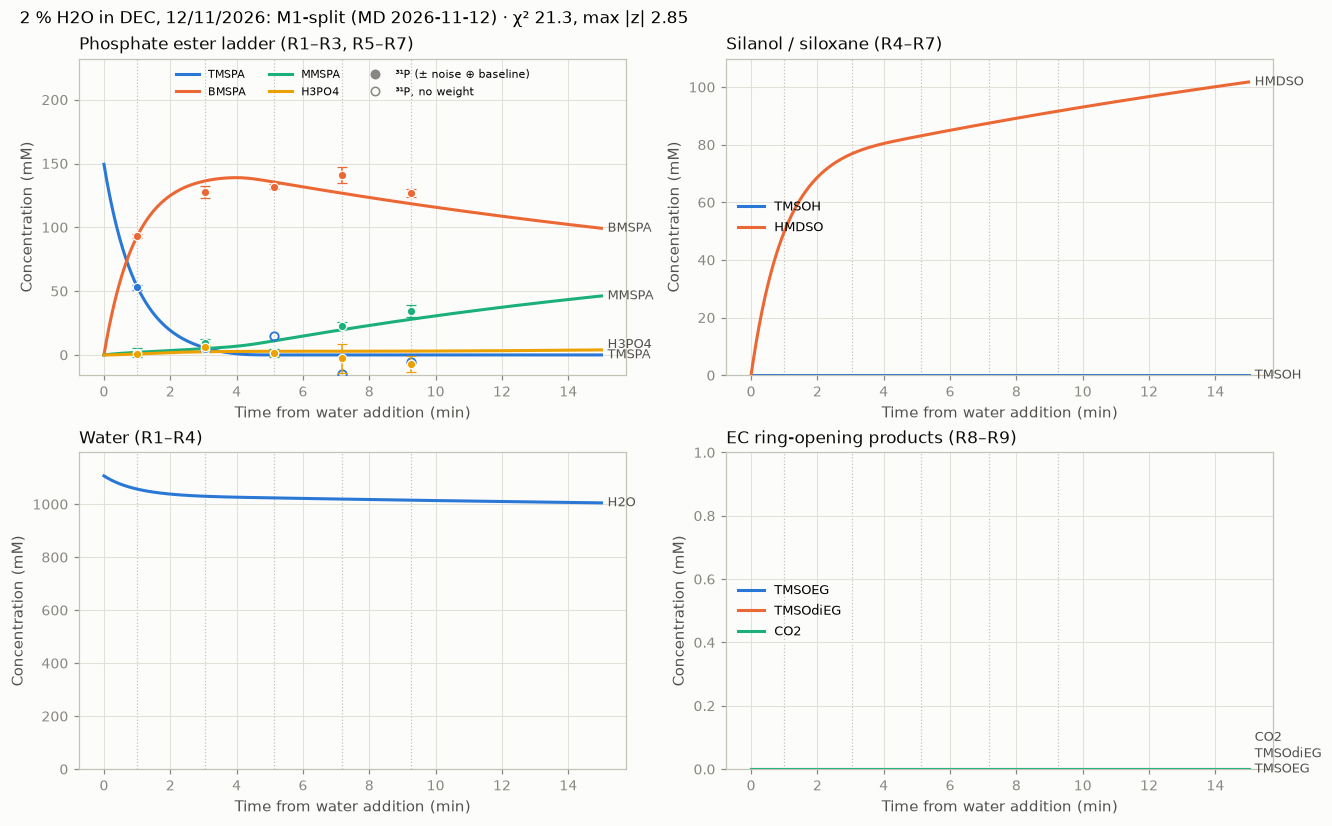

In [6]:
DEC_UNTIL_H = 0.25  # 15 min after water addition

runs_eval = {}
for label, path, fit_obj in [('M1', RUN_M1, fit_m1), ('M1-split', RUN_SPLIT, fit_sp)]:
    apply_fit_config(path)
    obs = load_lab_observables(str(path / 'data_dir' / 'data' / 'lab_observables.json'))
    ev = evaluate_fit(fit_obj, obs)
    runs_eval[label] = {
        'fit': fit_obj,
        'shares': tabulate_fit_shares(ev),
        'curve': simulate_fit_trajectories(ev, until_h=DEC_UNTIL_H, t_first_h=1e-6, n_points=600),
    }


def draw_dec_points(ax, shares, species, colour):
    seen = shares[shares['window'] == species]
    y = 1000.0 * seen['measured'] * seen['total_M']
    error = 1000.0 * seen['sigma_nmr'] * seen['total_M']
    weighted = seen['sigma_nmr'] < 1.0
    ax.errorbar(60.0 * seen['t_h'][weighted], y[weighted], yerr=error[weighted], fmt='o', color=colour, markersize=5.5,
                markeredgecolor=fit_plots.SURFACE, markeredgewidth=0.8, elinewidth=1.0, capsize=3, zorder=4)
    ax.plot(60.0 * seen['t_h'][~weighted], y[~weighted], 'o', markerfacecolor='none', markeredgecolor=colour,
            markersize=5.5, markeredgewidth=1.2, zorder=4)
    return y


for label in ('M1', 'M1-split'):
    d = runs_eval[label]
    curve, shares, best = d['curve'], d['shares'], d['fit']
    species = [c for c in curve.columns if c not in ('sample', 't_h', 'T_C')]
    sim = {
        'model': '',
        't_h': 60.0 * curve['t_h'].to_numpy(),
        'T_K': curve['T_C'].to_numpy() + ZERO_CELSIUS_K,
        'C_mM': 1000.0 * np.clip(curve[species].to_numpy().T, 0.0, None),
        'idx': {sp: i for i, sp in enumerate(species)},
        'acquisitions': [{'t_h': 60.0 * t} for t in shares['t_h'].unique()],
        'time_label': 'Time from water addition (min)',
    }
    fig = plot_concentration_panels(sim, from_zero=True)
    ax = fig.axes[0]
    low, high = ax.get_ylim()
    for k, sp in enumerate(CONCENTRATION_PANELS[0][1]):
        y = draw_dec_points(ax, shares, sp, style.SERIES[k])
        low, high = min(low, 1.08 * float(y.min())), max(high, 1.08 * float(y.max()))
    ax.set_ylim(low, low + 1.4 * (high - low))
    handles, _ = ax.get_legend_handles_labels()
    handles += [
        Line2D([], [], color=fit_plots.INK_MUTED, marker='o', linestyle='none', markersize=5.5, label='³¹P (± noise ⊕ baseline)'),
        Line2D([], [], color=fit_plots.INK_MUTED, marker='o', markerfacecolor='none', linestyle='none', markersize=5.5, label='³¹P, no weight'),
    ]
    ax.legend(handles=handles, loc='upper center', ncols=3, fontsize=7.5)
    fig.suptitle(f"{TUBE}: {label} (MD 2026-11-12) · χ² {best['chi2']:.1f}, max |z| {best['max_abs_z']:.2f}",
                 x=0.01, ha='left', fontsize=11)
    display(fig)
    plt.close(fig)

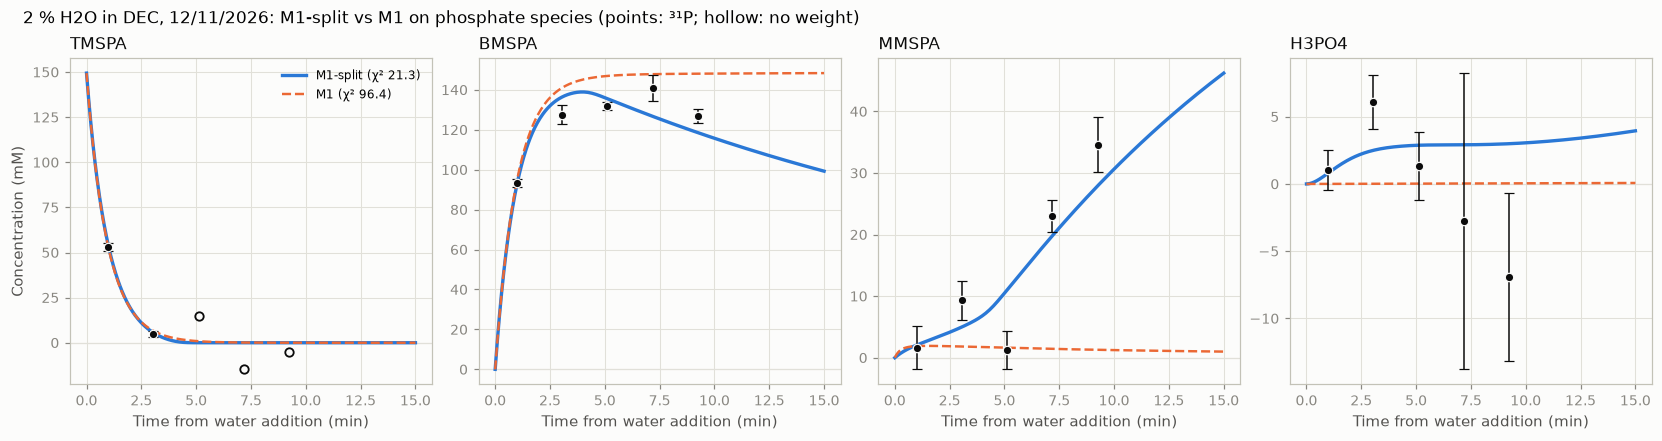

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), layout='constrained', sharex=True)
COMPARE = [('M1-split', '-', 2.2, style.SERIES[0]), ('M1', '--', 1.6, style.SERIES[1])]

for ax, sp in zip(axes, CONCENTRATION_PANELS[0][1]):
    for label, ls, lw, col in COMPARE:
        d = runs_eval[label]
        curve = d['curve']
        ax.plot(60.0 * curve['t_h'], 1000.0 * curve[sp].clip(lower=0.0), ls=ls, lw=lw, color=col,
                label=f"{label} (χ² {d['fit']['chi2']:.1f})")
    draw_dec_points(ax, runs_eval['M1-split']['shares'], sp, fit_plots.INK)
    ax.set_title(sp, loc='left')
    ax.set_xlabel('Time from water addition (min)')
    ax.axhline(0.0, color=fit_plots.GRID, lw=0.8, zorder=0)

axes[0].set_ylabel('Concentration (mM)')
axes[0].legend(loc='upper right', fontsize=8)
fig.suptitle(f'{TUBE}: M1-split vs M1 on phosphate species (points: ³¹P; hollow: no weight)',
             x=0.01, ha='left', fontsize=11)
display(fig)
plt.close(fig)

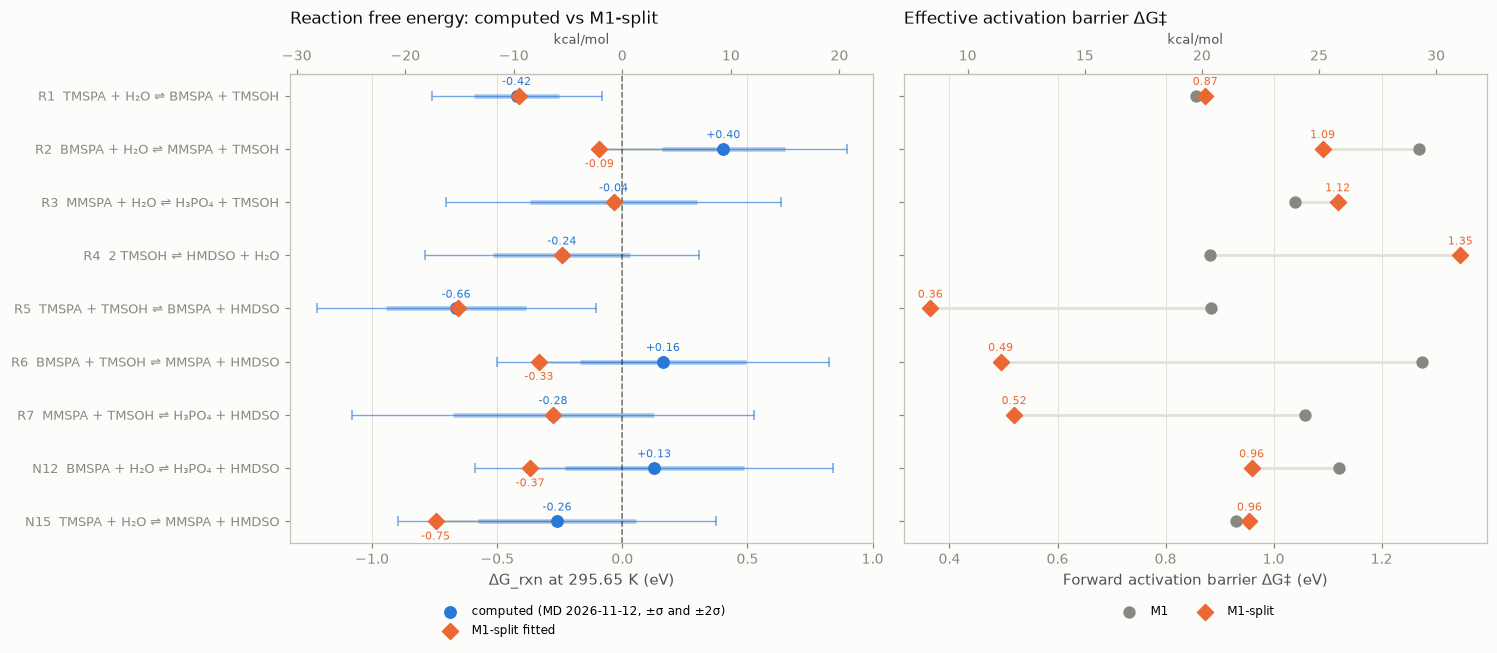

In [8]:
rows = rxn_df.iloc[::-1]
y = np.arange(len(rows))
C_COMP, C_SPLIT = style.SERIES[0], style.SERIES[1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 0.48 * len(rows) + 1.5), layout='constrained', sharey=True)

# Left: ΔG_rxn computed (±1σ, ±2σ) vs M1-split
for yi, (_, row) in zip(y, rows.iterrows()):
    ax1.plot([row['ΔG_rxn comp (eV)'], row['ΔG_rxn M1-split (eV)']], [yi, yi], color=fit_plots.GRID, lw=1.8, zorder=1)
ax1.errorbar(rows['ΔG_rxn comp (eV)'], y, xerr=2 * rows['σ_solv (eV)'], fmt='none', ecolor=C_COMP, elinewidth=0.9, capsize=3, alpha=0.65, zorder=2)
ax1.errorbar(rows['ΔG_rxn comp (eV)'], y, xerr=rows['σ_solv (eV)'], fmt='none', ecolor=C_COMP, elinewidth=3.0, capsize=0, alpha=0.4, zorder=2)
ax1.scatter(rows['ΔG_rxn comp (eV)'], y, color=C_COMP, s=55, zorder=3, label='computed (MD 2026-11-12, ±σ and ±2σ)')
ax1.scatter(rows['ΔG_rxn M1-split (eV)'], y, color=C_SPLIT, s=55, marker='D', zorder=4, label='M1-split fitted')
for yi, (_, row) in zip(y, rows.iterrows()):
    ax1.annotate(f"{row['ΔG_rxn comp (eV)']:+.2f}", (row['ΔG_rxn comp (eV)'], yi), xytext=(0, 7),
                 textcoords='offset points', ha='center', fontsize=7.5, color=C_COMP)
    if abs(row['ΔG_rxn M1-split (eV)'] - row['ΔG_rxn comp (eV)']) > 0.015:
        ax1.annotate(f"{row['ΔG_rxn M1-split (eV)']:+.2f}", (row['ΔG_rxn M1-split (eV)'], yi), xytext=(0, -12),
                     textcoords='offset points', ha='center', fontsize=7.5, color=C_SPLIT)
ax1.axvline(0, color=fit_plots.INK, lw=1, ls='--', alpha=0.55)
ax1.set_yticks(y, [f"{rid}  {eq}" for rid, eq in zip(rows.index, rows['Equation'])], fontsize=8.5)
ax1.set_xlabel('ΔG_rxn at 295.65 K (eV)')
ax1.set_title('Reaction free energy: computed vs M1-split', loc='left')
ax1.grid(axis='y', visible=False)
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.11), ncol=1, fontsize=8, frameon=False)
top1 = ax1.secondary_xaxis('top', functions=(lambda e: e / KCAL_EV, lambda k: k * KCAL_EV))
top1.set_xlabel('kcal/mol', fontsize=8.5)

# Right: ΔG‡ M1 vs M1-split
for yi, (_, row) in zip(y, rows.iterrows()):
    ax2.plot([row['ΔG‡ M1 (eV)'], row['ΔG‡ M1-split (eV)']], [yi, yi], color=fit_plots.GRID, lw=1.8, zorder=1)
ax2.scatter(rows['ΔG‡ M1 (eV)'], y, color=fit_plots.INK_MUTED, s=50, zorder=3, label='M1')
ax2.scatter(rows['ΔG‡ M1-split (eV)'], y, color=C_SPLIT, s=55, marker='D', zorder=4, label='M1-split')
for yi, (_, row) in zip(y, rows.iterrows()):
    ax2.annotate(f"{row['ΔG‡ M1-split (eV)']:.2f}", (row['ΔG‡ M1-split (eV)'], yi), xytext=(0, 7),
                 textcoords='offset points', ha='center', fontsize=7.5, color=C_SPLIT)
ax2.set_xlabel('Forward activation barrier ΔG‡ (eV)')
ax2.set_title('Effective activation barrier ΔG‡', loc='left')
ax2.grid(axis='y', visible=False)
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.11), ncol=2, fontsize=8, frameon=False)
top2 = ax2.secondary_xaxis('top', functions=(lambda e: e / KCAL_EV, lambda k: k * KCAL_EV))
top2.set_xlabel('kcal/mol', fontsize=8.5)

display(fig)
plt.close(fig)

### 3.4 MMSPA formation pathway in M1-split

$$\mathrm{BMSPA} + \mathrm{H_2O} \xrightarrow{\mathrm{N12\ (slow,\ R2+R3\ barrier)}} \mathrm{H_3PO_4} + \mathrm{HMDSO}$$

$$\mathrm{H_3PO_4} + \mathrm{HMDSO} \xrightarrow{\mathrm{R7\ rev\ (fast)}} \mathrm{MMSPA} + \mathrm{TMSOH}, \qquad \mathrm{BMSPA} + \mathrm{TMSOH} \xrightarrow{\mathrm{R6\ (fast)}} \mathrm{MMSPA} + \mathrm{HMDSO}$$

$$\mathrm{Net:}\quad 2\,\mathrm{BMSPA} + \mathrm{H_2O} \longrightarrow 2\,\mathrm{MMSPA} + \mathrm{HMDSO}$$